# Soluciones débiles y condición de Rankine–Hugoniot

**Complemento · Pesar lo que atraviesa una ventana.** Encierra un salto móvil $x=X(t)$ entre dos marcas fijas $A<B$, con estados constantes $u_L,u_R$. La masa allí es $(X-A)u_L+(B-X)u_R$. Su derivada es $X'(u_L-u_R)$, pero por las paredes entra $f(u_L)-f(u_R)$. Igualarlas obliga a la velocidad de Rankine–Hugoniot. Para un perfil discontinuo este balance todavía tiene sentido. La función de prueba $\varphi$ es una ventana suave en espacio y tiempo: integrar por partes traslada las derivadas a esa ventana e incorpora la masa inicial mediante el término en $t=0$.


Para una ley de conservación escalar

$$
u_t+f(u)_x=0,
$$

una función acotada es solución débil si, para toda $\varphi\in C_c^\infty(\mathbb R\times[0,\infty))$,

$$
\int_0^\infty\!\!\int_{\mathbb R}
\bigl(u\varphi_t+f(u)\varphi_x\bigr)\,dx\,dt
+\int_{\mathbb R}u_0(x)\varphi(x,0)\,dx=0.
$$

Esta formulación admite discontinuidades y expresa conservación sin diferenciar a $u$ punto por punto.


### Ejemplo gráfico complementario · Velocidad del salto

Fija un intervalo que contenga el frente durante la observación. El estado izquierdo vale $2$ y gana una longitud $h$ si el salto avanza $h$. La masa aumenta $2h$. Para Burgers el flujo de entrada es $2$ y el de salida $0$, de modo que el avance requiere un tiempo $h$. Por eso el desplazamiento horizontal del escalón mide la velocidad uno.


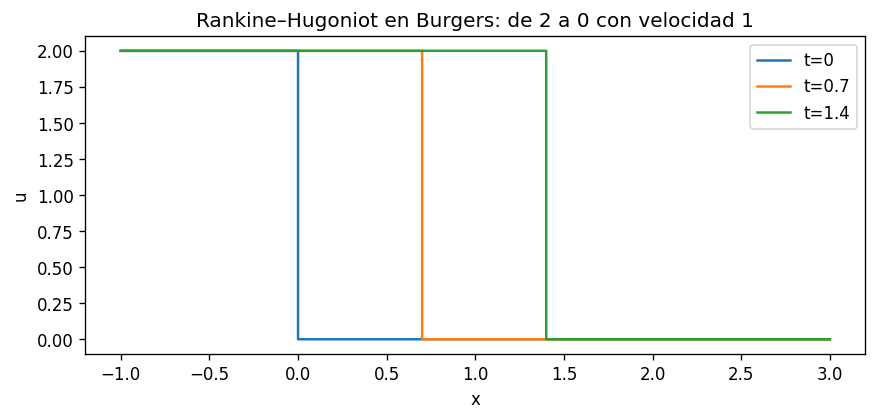

In [1]:
import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7.4,3.6))
x=np.linspace(-1,3,601)
for t in [0,0.7,1.4]:
    ax.step(x,np.where(x<t,2.,0.),where="post",label=f"t={t:g}")
ax.set(xlabel="x",ylabel="u",title="Rankine–Hugoniot en Burgers: de 2 a 0 con velocidad 1")
ax.legend()
fig.tight_layout()
plt.show()

## Salto móvil

Suponga que $u=u_L$ a la izquierda de $x=s t$ y $u=u_R$ a la derecha. Integrar la ley en un rectángulo que cruza el salto da

$$
s[u]=[f(u)],\qquad
s=\frac{f(u_R)-f(u_L)}{u_R-u_L},
$$

donde $[g]=g_R-g_L$. Esta condición es necesaria para que no se cree ni destruya masa sobre la discontinuidad.

Para Burgers, $f(u)=u^2/2$, de modo que $s=(u_L+u_R)/2$. Rankine–Hugoniot decide la velocidad, pero no la admisibilidad: para flujo convexo, un choque entrópico satisface $f'(u_L)>s>f'(u_R)$.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

uL, uR = 2.0, 0.0
s = 0.5 * (uL + uR)
x = np.linspace(-4, 4, 800)

fig, axes = plt.subplots(1, 3, figsize=(11, 3), sharey=True)
for ax, t in zip(axes, [0.0, 1.0, 2.0]):
    u = np.where(x < s*t, uL, uR)
    ax.plot(x, u, lw=2)
    ax.axvline(s*t, color="tab:red", ls="--", label=f"x=st")
    ax.set_title(f"t={t:g}")
    ax.set_xlabel("x")
axes[0].set_ylabel("u(x,t)")
axes[-1].legend()
plt.tight_layout()

## Ejercicios esenciales

1. Para $f(u)=u^3/3$ y estados $u_L=2$, $u_R=1$, calcule la velocidad de un salto y verifique la condición de Lax. Explique qué parte del argumento usa la convexidad local del flujo.
2. Demuestre directamente, usando la formulación débil, que una función constante a cada lado de $x=st$ es solución si y solo si satisface Rankine–Hugoniot.

### ★ Variación de nivel General

Considere $u_t+(u(1-u))_x=0$ con datos de Riemann $u_L=0.8$ y $u_R=0.2$.

a) Determine si la solución entrópica es choque o rarefacción teniendo en cuenta que el flujo es cóncavo.  
b) Si es choque, calcule su velocidad e interprete el signo en el modelo de tráfico. Si es rarefacción, determine sus velocidades extremas.  
c) Verifique conservación de masa en un intervalo móvil que contenga toda la onda.

## Lista de control

- No confundir solución débil con solución entrópica.
- Fijar una convención para $[g]$ y conservarla.
- En un flujo cóncavo, invertir mecánicamente la regla aprendida para Burgers conduce a errores; conviene comparar las velocidades características $f'(u_L)$ y $f'(u_R)$.